# R00 — Deterministic syntactic alignment after NS10

**Pilot, not a demonstrated neutralization method.** Start with the saved 54 NS10 texts. Use the existing 20 adaptation cases to select syntactic discrepancies; keep the other 34 separate for evaluation. Human references are **unrelated RAID training texts only**. Candidate prompts contain only the AI sentence and a generic restructuring instruction.

The algorithm minimizes two-sided syntactic band error plus joint RBF-MMD, never a RoBERTa score. It generates candidates with fixed beam search, checks lexical/content invariants and bidirectional entailment, then applies compatibility guards. All 54 outputs—including unchanged cases—are saved. The 34-case experiment is exploratory because those cases were examined in C07b.

**Run in a fresh kernel.** Generation, entailment, Qwen scoring, and RoBERTa evaluation load one model at a time. Use an environment with PyTorch, `transformers>=4.51.3,<5`, sentencepiece, spaCy + en_core_web_sm, pandas, numpy, scipy, matplotlib, pyarrow, huggingface_hub and packaging. Qwen3 requires a newer transformers than the Binoculars environment: do not upgrade that working environment in place. No package installation runs automatically here.

This is our proposed alignment extension, **not a reproduction of SCPN or Adversarial Paraphrasing**. FLAN-T5-base is the memory-conscious candidate generator; poor candidate quality or no admissible edit is an informative feasibility failure. RoBERTa models are evaluation-only. No new detector training, no NS10 overwrite, and no publication or repository push.


In [1]:
# %pip install "transformers==4.51.3"

In [2]:
from pathlib import Path
import os, sys, json, hashlib, tempfile, gc, re, math, time, importlib.metadata
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from functools import lru_cache
from difflib import SequenceMatcher
from scipy.spatial.distance import cdist
import torch, transformers, spacy
from packaging.version import Version
from huggingface_hub import HfApi
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, AutoModelForCausalLM
from IPython.display import display, HTML
assert Version(transformers.__version__) >= Version('4.51.3'), (
    'R00 requires transformers>=4.51.3 for its Qwen3 compatibility gate. '
    'Use a separate R00 kernel; preserve your Binoculars environment.')
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
    if (p/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1').exists()),None)
assert ROOT is not None, 'Open R00 inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C07=ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1'
AD=C07/'adaptation20_34_seed20260923'
NS_PATH=ROOT/'results/causal/C06b_NEW_steps5_10_v1/NS10_texts.csv'
OUT=ROOT/'results/causal/R00_syntactic_alignment_v1'
for sub in ['', 'cache', 'candidates', 'entailment', 'search', 'figures', 'roberta']:
    (OUT/sub).mkdir(parents=True,exist_ok=True)
CFG=dict(seed=20260924, passes=2, max_sentences=4, beams=4, returns=4,
    max_input_tokens=384, max_output_tokens=160, min_ref=20,
    active_z=.35, max_active_features=6, entailment_min=.80,
    max_sentence_edit_fraction=.40, max_document_edit_fraction=.15,
    min_improvement=1e-6, mmd_weight=.25,
    surface_z_tolerance=.25,
    U_tolerance=.25, tail_share_tolerance=.03,
    generator='google/flan-t5-base', nli='cross-encoder/nli-deberta-v3-small',
    scorer='Qwen/Qwen3-0.6B-Base')
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
DTYPE=torch.bfloat16 if DEVICE=='cuda' and torch.cuda.is_bf16_supported() else torch.float32
torch.manual_seed(CFG['seed']);np.random.seed(CFG['seed'])
torch.use_deterministic_algorithms(True)
if DEVICE=='cuda':
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
nlp=spacy.load('en_core_web_sm')
assert {'parser','tagger','lemmatizer','ner'} <= set(nlp.pipe_names)

def sha(x): return hashlib.sha256(str(x).encode()).hexdigest()
def digest(x):return sha(json.dumps(x,sort_keys=True,ensure_ascii=False))
def file_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def atomic_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            json.dump(value,f,sort_keys=True,indent=2,allow_nan=False)
            f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def save_csv(df,path):
    path=Path(path);fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            df.to_csv(f,index=False);f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def freeze(path,value):
    if path.exists():assert json.loads(path.read_text())==value, f'Changed protocol: choose a new OUT. {path}'
    else:atomic_json(path,value)
def release():
    gc.collect()
    if DEVICE=='cuda':torch.cuda.empty_cache()
print('Output:',OUT,'| device:',DEVICE,'| no detector used during editing')


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output: ../results/causal/R00_syntactic_alignment_v1 | device: cuda | no detector used during editing


## 1. Source integrity and reference separation

Reference fitting uses half of each genre's unrelated training humans; the other half is a reference check. Exclusion uses the RAID source-group key for **all 54 cases**, so their matched human texts never enter the reference pool. Documents of any length remain intact; length is conditioned on through a training-human regression. The two attack partitions have independent batch objectives.


In [3]:
split=json.loads((AD/'split.json').read_text())
dev_ids=sorted(map(str,split['adaptation_cases']));test_ids=sorted(map(str,split['test_cases']))
assert len(dev_ids)==20 and len(test_ids)==34 and not set(dev_ids)&set(test_ids)
ns=pd.read_csv(NS_PATH,keep_default_na=False).sort_values('case_id').reset_index(drop=True)
ns['case_id']=ns.case_id.astype(str)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert set(ns.case_id)==set(dev_ids+test_ids)
assert ns.text.map(sha).eq(ns.text_sha).all()
ns['partition']=np.where(ns.case_id.isin(dev_ids),'development20','heldout34')
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet',columns=['source_id','text'])
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','label','split','domain']].copy()
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'label'].eq(1).all() and rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
def source_group(s):return str(s).split('__',1)[-1]
blocked={source_group(s) for s in ns.source_id}
humans=raid.loc[raid.label.eq(0)&raid.split.eq('train')].copy()
humans=humans.loc[~humans.source_id.map(source_group).isin(blocked)].copy()
humans['order']=humans.source_id.map(lambda s:sha('R00-reference-'+s))
refs=[]
for domain,frame in humans.groupby('domain',sort=True):
    frame=frame.sort_values('order').copy()
    frame['reference_role']=['fit' if i%2==0 else 'check' for i in range(len(frame))]
    refs.append(frame)
humans=pd.concat(refs,ignore_index=True)
assert not set(humans.source_id.map(source_group))&blocked
save_csv(humans.drop(columns=['text','order']),OUT/'reference_manifest.csv')
save_csv(ns.drop(columns='text'),OUT/'input_manifest.csv')
display(humans.groupby(['domain','reference_role']).size().unstack(fill_value=0))
# Resolve once; preserve exact model revisions for all subsequent reruns.
pin_path=OUT/'model_pins.json'
if pin_path.exists():pins=json.loads(pin_path.read_text())
else:
    pins={name:HfApi().model_info(CFG[name]).sha for name in ['generator','nli','scorer']}
    atomic_json(pin_path,pins)
SELF=ROOT/'experiments/R00_deterministic_syntactic_alignment.ipynb'
if not SELF.exists():SELF=Path.cwd()/'R00_deterministic_syntactic_alignment.ipynb'
assert SELF.exists(),'Save this notebook under experiments/ or the working directory first.'
notebook=json.loads(SELF.read_text())
code_hash=digest([''.join(c['source']) for c in notebook['cells'] if c['cell_type']=='code'])
PROTOCOL=dict(version=1,config=CFG,pins=pins,code_hash=code_hash,
    ns_sha=file_sha(NS_PATH),split_sha=file_sha(AD/'split.json'),
    references=[dict(source_id=r.source_id,text_sha=sha(r.text),role=r.reference_role) for r in humans.itertuples()],
    parser=nlp.meta,packages={p:importlib.metadata.version(p) for p in
        ['torch','transformers','spacy','numpy','pandas','scipy']},device=DEVICE,dtype=str(DTYPE))
freeze(OUT/'protocol.json',PROTOCOL);RUN_SHA=digest(PROTOCOL)
del meta,corpus,rm,refs,notebook;release()


reference_role,check,fit
domain,,
abstracts,52,53
books,42,42
news,58,59
poetry,23,23
recipes,49,50
reddit,35,36
reviews,14,14
wiki,43,43


## 2. Fixed syntactic measurements and protected surface measurements

The syntactic features describe coordination, subordination, dependency depth/distance and connective placement. They are **hypothesis-driven proxies**, not claimed to be RoBERTa's complete representation. The protected surface vector covers counts, punctuation, lexical diversity, POS moments and ORG/CARDINAL sentence moments; it is not a bit-for-bit replacement for every historical FZ feature.

Human residuals are conditioned on log word count within genre. Two-sided bands are the 10th–90th training-human residual percentiles. Active dimensions are chosen using only development20: an absolute standardized mean gap ≥0.35, up to six per genre. If a genre lacks reference support or no feature crosses the cutoff, its texts remain unchanged. This threshold is an exploratory engineering choice, not a significance test.


In [4]:
SYN_NAMES=['coord_clause_rate','adv_clause_rate','relative_clause_rate','complement_clause_rate',
    'mean_depth','max_depth','mean_dependency_distance','coord_span_share',
    'CCONJ_initial_rate','ADP_initial_rate','comma_before_connective_rate',
    'connective_mean_position','connective_position_sd','CCONJ_rate','SCONJ_rate','ADP_rate']
PUNCT={'comma':',','semicolon':';','colon':':','hyphen':'-','emdash':'—','endash':'–',
       'period':'.','question':'?','exclamation':'!'}
POS=['ADJ','ADP','ADV','AUX','CCONJ','DET','INTJ','NOUN','NUM','PART','PRON','PROPN','SCONJ','VERB']

def extract(text):
    d=nlp(text);sentences=[s for s in d.sents if any(t.is_alpha for t in s)]
    words=[t for t in d if t.is_alpha];W=max(1,len(words));S=max(1,len(sentences))
    depth=[len(list(t.ancestors)) for t in words]
    conn=[t for t in words if t.pos_ in {'CCONJ','SCONJ','ADP'}]
    positions=[(t.i-t.sent.start)/max(1,len(t.sent)-1) for t in conn]
    clauses=[t for t in d if t.dep_=='conj' and t.pos_ in {'VERB','AUX'}]
    counts=Counter(t.dep_ for t in words)
    syn=[len(clauses)/S, counts['advcl']/S, counts['relcl']/S,
         (counts['ccomp']+counts['xcomp'])/S,
         float(np.mean(depth)) if depth else 0.,max(depth,default=0),
         float(np.mean([abs(t.i-t.head.i) for t in words])) if words else 0.,
         float(np.mean([len(list(t.subtree))/max(1,len(t.sent)) for t in clauses])) if clauses else 0.,
         sum(s[0].pos_=='CCONJ' for s in sentences)/S,
         sum(s[0].pos_=='ADP' for s in sentences)/S,
         sum(t.i>0 and d[t.i-1].text==',' for t in conn)/max(1,len(conn)),
         float(np.mean(positions)) if positions else 0.,float(np.std(positions)) if positions else 0.,
         *[sum(t.pos_==p for t in words)/W for p in ['CCONJ','SCONJ','ADP']]]
    surf={'words':len(words),'sentences':len(sentences),'characters':len(text),
          'unique_share':len({t.lower_ for t in words})/W,
          'short_share':sum(len(t.text)<=3 for t in words)/W,
          'long_share':sum(len(t.text)>=7 for t in words)/W,
          'wps':len(words)/S,'cps':len(text)/S,'cpw':len(text)/W}
    for name,char in PUNCT.items():
        surf[name+'_per_sentence']=text.count(char)/S
    for p in POS:
        a=np.array([sum(t.pos_==p for t in s if not t.is_space) for s in sentences],float)
        surf[p+'_share']=sum(t.pos_==p for t in d)/max(1,sum(not t.is_space for t in d))
        surf[p+'_sentence_mean']=float(a.mean()) if len(a) else 0.
        surf[p+'_sentence_sd']=float(a.std()) if len(a) else 0.
        surf[p+'_sentence_max']=float(a.max()) if len(a) else 0.
    for label in ['ORG','CARDINAL']:
        a=[sum(e.label_==label for e in s.ents) for s in sentences]
        surf[label+'_entity_mean']=float(np.mean(a)) if a else 0.
    return dict(syntax=syn,surface=surf,words=len(words),
                sentences=[dict(start=s.start_char,end=s.end_char,text=s.text) for s in sentences])

def features(text):
    path=OUT/'cache'/('features_'+digest([RUN_SHA,sha(text)])+'.json')
    if not path.exists():atomic_json(path,extract(text))
    return json.loads(path.read_text())

# Cache references and AI texts separately; no human strings enter editing prompts.
for frame,name in [(humans,'human references'),(ns,'NS10')]:
    for i,r in enumerate(frame.itertuples(),1):
        features(r.text)
        if i%50==0:print(name,i,'/',len(frame),flush=True)
SURFACE_NAMES=sorted(features(ns.iloc[0].text)['surface'])

def design(text):return np.array([1.,np.log1p(features(text)['words'])])
def vector(text,kind):
    f=features(text)
    return np.asarray(f['syntax'] if kind=='syntax' else [f['surface'][k] for k in SURFACE_NAMES],float)
MODELS={};audit=[]
for domain in sorted(ns.domain.unique()):
    fit=humans.loc[humans.domain.eq(domain)&humans.reference_role.eq('fit')]
    check=humans.loc[humans.domain.eq(domain)&humans.reference_role.eq('check')]
    if min(len(fit),len(check))<CFG['min_ref']:
        print(domain,': insufficient human reference support; will retain NS10.');continue
    pack={}
    for kind in ['syntax','surface']:
        A=np.stack([design(t) for t in fit.text]);Y=np.stack([vector(t,kind) for t in fit.text])
        coef=np.linalg.lstsq(A,Y,rcond=None)[0];residual=Y-A@coef
        scale=np.maximum(np.std(residual,axis=0),.01)
        z=residual/scale;low,high=np.quantile(z,[.1,.9],axis=0)
        pack[kind]=dict(coef=coef,scale=scale,low=low,high=high,H=z)
    dev=ns.loc[ns.domain.eq(domain)&ns.partition.eq('development20')]
    def local_z(t):
        m=pack['syntax'];return (vector(t,'syntax')-design(t)@m['coef'])/m['scale']
    gap=np.mean([local_z(t) for t in dev.text],axis=0) if len(dev) else np.zeros(len(SYN_NAMES))
    eligible=[j for j in range(len(SYN_NAMES)) if abs(gap[j])>=CFG['active_z']]
    active=sorted(sorted(eligible,key=lambda j:(-abs(gap[j]),j))[:CFG['max_active_features']])
    pack['active']=active;MODELS[domain]=pack
    for j,name in enumerate(SYN_NAMES):
        audit.append(dict(domain=domain,feature=name,development_mean_z=float(gap[j]),active=j in active))
AUDIT=pd.DataFrame(audit,columns=['domain','feature','development_mean_z','active'])
save_csv(AUDIT,OUT/'development_feature_audit.csv');display(AUDIT.loc[AUDIT.active])

def zvector(text,domain,kind='syntax'):
    m=MODELS[domain][kind];return (vector(text,kind)-design(text)@m['coef'])/m['scale']
def band_loss(text,domain):
    m=MODELS[domain]['syntax'];ix=MODELS[domain]['active']
    if not ix:return 0.
    z=zvector(text,domain)[ix]
    return float(np.mean(np.maximum(np.maximum(m['low'][ix]-z,z-m['high'][ix]),0.)**2))
def rbf(A,B,sigma):return np.exp(-cdist(A,B,'sqeuclidean')/(2*sigma*sigma))
def mmd(A,B,sigma):
    # Biased nonnegative empirical MMD^2; null-calibrated at the same batch size.
    return float(max(0.,rbf(A,A,sigma).mean()+rbf(B,B,sigma).mean()-2*rbf(A,B,sigma).mean()))
for domain,pack in MODELS.items():
    ix=pack['active']
    if not ix:continue
    H=pack['syntax']['H'][:,ix];dist=cdist(H,H)
    positive=dist[np.triu_indices(len(H),1)];positive=positive[positive>1e-8]
    sigma=float(np.median(positive)) if len(positive) else 1.
    pack['sigma']=sigma;pack['null']={}
    # Fit-only resampling sets the objective scale; reference-check humans stay untouched.
    C=H
    for partition in ['development20','heldout34']:
        n=int((ns.domain.eq(domain)&ns.partition.eq(partition)).sum())
        if not n:continue
        rng=np.random.default_rng(CFG['seed'])
        null=[mmd(C[rng.integers(0,len(C),n)],H,sigma) for _ in range(500)]
        pack['null'][partition]=max(float(np.quantile(null,.95)),1e-6)

def objective(texts,domain,partition):
    pack=MODELS[domain];ix=pack['active']
    if not ix:return 0.
    X=np.stack([zvector(t,domain)[ix] for t in texts]);H=pack['syntax']['H'][:,ix]
    return float(np.mean([band_loss(t,domain) for t in texts])+
        CFG['mmd_weight']*mmd(X,H,pack['sigma'])/pack['null'][partition])
print('Active dimensions:',int(AUDIT.active.sum()),'| no RoBERTa scores inspected')


human references 50 / 636
human references 100 / 636
human references 150 / 636
human references 200 / 636
human references 250 / 636
human references 300 / 636
human references 350 / 636
human references 400 / 636
human references 450 / 636
human references 500 / 636
human references 550 / 636
human references 600 / 636
NS10 50 / 54
reviews : insufficient human reference support; will retain NS10.


,domain,feature,development_mean_z,active
4,abstracts,mean_depth,2.146268,True
5,abstracts,max_depth,1.270518,True
8,abstracts,CCONJ_initial_rate,2.538291,True
9,abstracts,ADP_initial_rate,-1.462283,True
12,abstracts,connective_position_sd,-1.844930,True
15,abstracts,ADP_rate,1.637226,True
16,books,coord_clause_rate,-0.992380,True
20,books,mean_depth,1.388395,True
21,books,max_depth,0.718330,True
24,books,CCONJ_initial_rate,3.645764,True


Active dimensions: 36 | no RoBERTa scores inspected


## 3. Finite candidate pool — deterministic beams, no human text in prompts

Two generic prompts × four beams produce at most eight distinct alternatives per selected sentence. Sentence selection uses a fixed structural complexity ranking, **not detector attribution**. Candidates always originate from NS10; the second search pass revisits this same finite pool instead of recursively paraphrasing paraphrases. Original sentence boundaries stay fixed, and no sentence split/merge is permitted in this conservative pilot.

Cheap guards lock named entities/proper names, numeral expressions, negation/modal markers and content-word lemma counts. This intentionally restrictive starting point favors structural reorderings over lexical replacement. Its rejection rate is reported; a no-edit outcome is not called success.


In [5]:
PROMPTS=[
    'Rewrite this sentence with a different clause order and grammatical structure. Preserve exactly its facts, names, numbers, negation, and content words. Return one complete sentence only: ',
    'Rephrase this sentence by reorganizing its clauses and connective placement while preserving the same meaning and content words. Return one complete sentence only: ']
CANDIDATE_SPEC=digest([RUN_SHA,PROMPTS])

def candidate_path(cid):return OUT/'candidates'/(cid+'.json')
def edit_fraction(a,b):
    x=re.findall(r"\w+|[^\w\s]",a);y=re.findall(r"\w+|[^\w\s]",b)
    matcher=SequenceMatcher(a=x,b=y,autojunk=False)
    edits=sum(max(j-i,l-k) for tag,i,j,k,l in matcher.get_opcodes() if tag!='equal')
    return edits/max(1,len(x))
def invariants(text):
    d=nlp(text)
    return dict(
        entities=sorted((e.label_,e.text.lower()) for e in d.ents),
        proper=sorted(t.lower_ for t in d if t.pos_=='PROPN'),
        numbers=sorted(t.lower_ for t in d if t.like_num),
        polarity=sorted(t.lower_ for t in d if t.dep_=='neg' or t.lower_ in
            {'no','never','without','unless','if','may','might','must','could','should','would','can'}),
        content=sorted(t.lemma_.lower() for t in d if t.pos_ in {'NOUN','VERB','ADJ','ADV'}))
def cheap_guard(original,candidate):
    if candidate==original:return 'unchanged'
    if not candidate.strip():return 'empty'
    if any(ord(c)<32 and c not in '\n\t\r' for c in candidate):return 'control_character'
    if any(c in candidate for c in ['\u200b','\u200c','\u200d','\ufeff']):return 'invisible_character'
    # Beam generator may return labels/quotes or multiple sentences: reject rather than silently fix.
    if len(features(candidate)['sentences'])!=1:return 'sentence_count'
    if invariants(original)!=invariants(candidate):return 'content_invariants'
    if edit_fraction(original,candidate)>CFG['max_sentence_edit_fraction']:return 'edit_budget'
    return 'eligible'

pending=[]
for r in ns.itertuples():
    path=candidate_path(r.case_id)
    if path.exists():assert json.loads(path.read_text())['spec']==CANDIDATE_SPEC;continue
    pack=MODELS.get(r.domain)
    if pack is None or not pack['active']:
        atomic_json(path,dict(spec=CANDIDATE_SPEC,case_id=r.case_id,items=[],status='no_active_feature'));continue
    pending.append(r)
if pending:
    gen_tok=AutoTokenizer.from_pretrained(CFG['generator'],revision=pins['generator'])
    gen_model=AutoModelForSeq2SeqLM.from_pretrained(CFG['generator'],revision=pins['generator'],
        torch_dtype=DTYPE,attn_implementation='eager',low_cpu_mem_usage=True).to(DEVICE).eval()
    for r in pending:
        ranked=[]
        for si,s in enumerate(features(r.text)['sentences']):
            d=nlp(s['text'])
            priority=sum(t.dep_ in {'conj','advcl','relcl','ccomp','xcomp'} for t in d)
            ranked.append((-priority,si,s))
        items=[]
        # Sub-sentence caches retain generation if interruption occurs mid-document.
        for _,si,s in sorted(ranked)[:CFG['max_sentences']]:
            raw=[]
            for prompt_i,prefix in enumerate(PROMPTS):
                prompt=prefix+s['text']
                p=OUT/'cache'/('beam_'+digest([CANDIDATE_SPEC,prompt])+'.json')
                if p.exists():outputs=json.loads(p.read_text())
                else:
                    encoded=gen_tok(prompt,return_tensors='pt',truncation=False)
                    if encoded.input_ids.shape[1]>CFG['max_input_tokens']:outputs=[]
                    else:
                        with torch.inference_mode():
                            out=gen_model.generate(**encoded.to(DEVICE),do_sample=False,
                                num_beams=CFG['beams'],num_return_sequences=CFG['returns'],
                                max_new_tokens=CFG['max_output_tokens'],early_stopping=True)
                        outputs=gen_tok.batch_decode(out,skip_special_tokens=True)
                    atomic_json(p,outputs)
                raw.extend(outputs)
            for candidate in sorted(set(t.strip() for t in raw)):
                reason=cheap_guard(s['text'],candidate)
                items.append(dict(sentence_index=si,start=s['start'],end=s['end'],
                    original=s['text'],candidate=candidate,cheap_status=reason,
                    key=digest([s['text'],candidate])))
        atomic_json(candidate_path(r.case_id),dict(spec=CANDIDATE_SPEC,case_id=r.case_id,
            items=items,status='generated'))
        print(r.case_id,'saved',len(items),'candidates',flush=True)
    del gen_model,gen_tok;release()
all_candidates=[dict(case_id=r.case_id,**item) for r in ns.itertuples()
    for item in json.loads(candidate_path(r.case_id).read_text())['items']]
candidate_table=pd.DataFrame(all_candidates)
if len(candidate_table):display(candidate_table.cheap_status.value_counts().to_frame('candidates'))
else:print('No active syntactic discrepancy to edit; downstream outputs will retain NS10.')


gate_0001 saved 22 candidates
gate_0003 saved 22 candidates
gate_0004 saved 25 candidates
gate_0005 saved 26 candidates
gate_0007 saved 24 candidates
gate_0015 saved 22 candidates
gate_0016 saved 21 candidates
gate_0017 saved 25 candidates
gate_0018 saved 28 candidates
gate_0019 saved 24 candidates
gate_0021 saved 19 candidates
gate_0022 saved 27 candidates
gate_0023 saved 24 candidates
gate_0024 saved 24 candidates
gate_0025 saved 23 candidates
gate_0026 saved 21 candidates
gate_0027 saved 23 candidates
gate_0028 saved 23 candidates
gate_0030 saved 21 candidates
gate_0035 saved 22 candidates
gate_0037 saved 26 candidates
gate_0038 saved 25 candidates
gate_0039 saved 22 candidates
gate_0046 saved 25 candidates
gate_0047 saved 27 candidates
gate_0048 saved 25 candidates
gate_0049 saved 22 candidates
gate_0050 saved 23 candidates
gate_0051 saved 25 candidates
gate_0054 saved 26 candidates
gate_0062 saved 19 candidates
gate_0065 saved 25 candidates
gate_0066 saved 26 candidates
gate_0067 

,candidates
cheap_status,
content_invariants,816
eligible,299
unchanged,108
sentence_count,28
edit_budget,2


## 4. Meaning-preservation screen

A small NLI model evaluates entailment in both directions between the original AI sentence and its candidate. This is a **semantic consistency screen**, not fact checking against human material and not proof of equivalence. Invalid or overlength inputs are rejected. Manual review remains part of the output.


In [6]:
eligible={x['key']:x for x in all_candidates if x['cheap_status']=='eligible'}
missing=[x for key,x in sorted(eligible.items()) if not (OUT/'entailment'/(key+'.json')).exists()]
if missing:
    nli_tok=AutoTokenizer.from_pretrained(CFG['nli'],revision=pins['nli'])
    nli_model=AutoModelForSequenceClassification.from_pretrained(CFG['nli'],revision=pins['nli'],
        torch_dtype=DTYPE,low_cpu_mem_usage=True).to(DEVICE).eval()
    mapping={int(k):str(v).lower() for k,v in nli_model.config.id2label.items()}
    entail=[k for k,v in mapping.items() if 'entail' in v]
    # Official model card specifies 0=contradiction, 1=entailment, 2=neutral.
    if not entail and set(mapping.values())=={'label_0','label_1','label_2'}:entail=[1]
    assert len(entail)==1, mapping
    for i,item in enumerate(missing,1):
        vals=[]
        for a,b in [(item['original'],item['candidate']),(item['candidate'],item['original'])]:
            enc=nli_tok(a,b,return_tensors='pt',truncation=False)
            if enc.input_ids.shape[1]>512:vals.append(0.);continue
            with torch.inference_mode():logits=nli_model(**enc.to(DEVICE)).logits
            vals.append(float(logits.float().softmax(-1)[0,entail[0]].cpu()))
        atomic_json(OUT/'entailment'/(item['key']+'.json'),dict(spec=RUN_SHA,
            forward=vals[0],reverse=vals[1],accepted=min(vals)>=CFG['entailment_min']))
        if i%25==0:print('Entailment',i,'/',len(missing),flush=True)
    del nli_model,nli_tok;release()
valid={}
for r in ns.itertuples():
    valid[r.case_id]=[]
    for item in json.loads(candidate_path(r.case_id).read_text())['items']:
        if item['cheap_status']!='eligible':continue
        status=json.loads((OUT/'entailment'/(item['key']+'.json')).read_text())
        assert status['spec']==RUN_SHA
        if status['accepted']:valid[r.case_id].append(item)
print('Meaning-screened candidates:',sum(map(len,valid.values())))


Entailment 25 / 299
Entailment 50 / 299
Entailment 75 / 299
Entailment 100 / 299
Entailment 125 / 299
Entailment 150 / 299
Entailment 175 / 299
Entailment 200 / 299
Entailment 225 / 299
Entailment 250 / 299
Entailment 275 / 299
Meaning-screened candidates: 280


## 5. Deterministic distribution search with atomic progress

Each development/held-out × genre batch is optimized independently. Accept strict improvement of the specified objective only. Surface constraints are measured relative to the original NS10 text, not cumulatively relaxed. For every protected feature, deviation from its human interval may increase by at most 0.25 reference SD, and total standardized movement is limited. These are pilot tolerances; they do not establish compatibility with every previous detector.

Every candidate decision is checkpointed, including rejected decisions. A run lock prevents concurrent writers. Text already inside the chosen syntactic bands can still be considered for a joint-distribution improvement, but per-case band error may not worsen.


In [7]:
import fcntl
from contextlib import contextmanager
@contextmanager
def run_lock():
    with (OUT/'run.lock').open('a+') as lock:
        fcntl.flock(lock.fileno(),fcntl.LOCK_EX|fcntl.LOCK_NB)
        try:yield
        finally:fcntl.flock(lock.fileno(),fcntl.LOCK_UN)

def violation(z,low,high):return np.maximum(np.maximum(low-z,z-high),0.)
def surface_guard(original,candidate,domain):
    m=MODELS[domain]['surface'];a=zvector(original,domain,'surface');b=zvector(candidate,domain,'surface')
    if np.any(violation(b,m['low'],m['high']) > violation(a,m['low'],m['high'])+CFG['surface_z_tolerance']):
        return False
    # Permit up to one SD total movement per dimension, while guarding band departures.
    if np.max(np.abs(b-a))>1.:return False
    old=features(original)['surface'];new=features(candidate)['surface']
    if old['sentences']!=new['sentences']:return False
    return edit_fraction(original,candidate)<=CFG['max_document_edit_fraction']

def render(original,replacements):
    text=original
    for key,item in sorted(replacements.items(),key=lambda kv:kv[1]['start'],reverse=True):
        text=text[:item['start']]+item['candidate']+text[item['end']:]
    return text

with run_lock():
    for (partition,domain),group in ns.groupby(['partition','domain'],sort=True):
        group=group.sort_values('case_id');base=group.set_index('case_id').text.to_dict()
        path=OUT/'search'/(partition+'__'+domain+'.json')
        if path.exists():state=json.loads(path.read_text());assert state['spec']==RUN_SHA
        else:
            state=dict(spec=RUN_SHA,done=[],replacements={cid:{} for cid in base},log=[])
            atomic_json(path,state)
        done=set(state['done'])
        if domain in MODELS and MODELS[domain]['active']:
            for pass_i in range(CFG['passes']):
                for cid in sorted(base):
                    for item in sorted(valid[cid],key=lambda x:(x['sentence_index'],x['candidate'])):
                        key=f'{pass_i}:{cid}:{item["key"]}'
                        if key in done:continue
                        current={c:render(base[c],state['replacements'][c]) for c in sorted(base)}
                        trial=dict(state['replacements'][cid]);trial[str(item['sentence_index'])]=item
                        candidate=render(base[cid],trial);accepted=False;reason='surface_guard'
                        before=objective(list(current.values()),domain,partition);after=before
                        if candidate==current[cid]:reason='unchanged'
                        elif surface_guard(base[cid],candidate,domain):
                            if band_loss(candidate,domain)>band_loss(current[cid],domain)+1e-9:reason='band_worse'
                            else:
                                trial_texts=dict(current);trial_texts[cid]=candidate
                                after=objective(list(trial_texts.values()),domain,partition)
                                accepted=after<before-CFG['min_improvement']
                                reason='accepted' if accepted else 'no_objective_gain'
                        if accepted:state['replacements'][cid]=trial
                        state['log'].append(dict(case_id=cid,pass_index=pass_i,key=item['key'],
                            accepted=accepted,reason=reason,before=before,after=after))
                        state['done'].append(key);done.add(key);atomic_json(path,state)
                    print(partition,domain,'pass',pass_i+1,cid,'saved',flush=True)
        state['complete']=True;atomic_json(path,state)

rows=[];logs=[]
for (partition,domain),group in ns.groupby(['partition','domain'],sort=True):
    state=json.loads((OUT/'search'/(partition+'__'+domain+'.json')).read_text())
    logs.extend(state['log'])
    for r in group.itertuples():
        text=render(r.text,state['replacements'][r.case_id])
        rows.append(dict(case_id=r.case_id,source_id=r.source_id,domain=domain,partition=partition,
            text=text,text_sha=sha(text),input_sha=sha(r.text),changed=text!=r.text,
            edited_sentences=len(state['replacements'][r.case_id]),pipeline_status='candidate'))
candidates=pd.DataFrame(rows).sort_values('case_id').reset_index(drop=True)
save_csv(candidates,OUT/'R11_candidate_texts.csv')
save_csv(pd.DataFrame(logs),OUT/'search_decisions.csv')
display(candidates.groupby('partition').agg(cases=('case_id','size'),changed=('changed','sum')))


development20 abstracts pass 1 gate_0069 saved
development20 abstracts pass 1 gate_0074 saved
development20 abstracts pass 1 gate_0079 saved
development20 abstracts pass 2 gate_0069 saved
development20 abstracts pass 2 gate_0074 saved
development20 abstracts pass 2 gate_0079 saved
development20 books pass 1 gate_0016 saved
development20 books pass 1 gate_0023 saved
development20 books pass 2 gate_0016 saved
development20 books pass 2 gate_0023 saved
development20 news pass 1 gate_0003 saved
development20 news pass 1 gate_0024 saved
development20 news pass 1 gate_0030 saved
development20 news pass 1 gate_0066 saved
development20 news pass 1 gate_0076 saved
development20 news pass 1 gate_0093 saved
development20 news pass 1 gate_0095 saved
development20 news pass 2 gate_0003 saved
development20 news pass 2 gate_0024 saved
development20 news pass 2 gate_0030 saved
development20 news pass 2 gate_0066 saved
development20 news pass 2 gate_0076 saved
development20 news pass 2 gate_0093 saved


,cases,changed
partition,,
development20,20,17
heldout34,34,20


## 6. Qwen compatibility gate and final R11 outputs

Recompute NS10 and candidate texts with the same Qwen3 scorer in this run. U128 uses targets 128 and 255 (zero-based); an eight-target estimate is also checked. These are explicitly recomputed R00 estimates, not silently substituted for saved U04 outputs. Token edits can change target identities; report the limitation. The full-prefix surprisal tail shares are measured over the first 512 scorer tokens.

A candidate is reverted to NS10 if either U estimate moves by more than 0.25 nats, common U eligibility is lost, or a tail share (>4, >6, >8 nats) moves by more than 3 percentage points. If both texts are too short for U128, a changed candidate is reverted because structural compatibility cannot be checked. Whole-genre/partition batches are also reverted if these individual rollbacks erase the net syntactic objective improvement.

These gates protect specified measurements, **not all Ghostbuster/WaveDetect/Binoculars outputs**. The final output is compatible with downstream scorers, but detector-wide compatibility and fresh adaptation remain separate experiments.


In [8]:
temporal_spec=digest([RUN_SHA,'U128_targets_128_255_and_linspace8','prefix512'])
def temporal_path(text):return OUT/'cache'/('temporal_'+digest([temporal_spec,sha(text)])+'.json')
texts=list(dict.fromkeys(ns.text.tolist()+candidates.text.tolist()))
missing=[t for t in texts if not temporal_path(t).exists()]
if missing:
    qtok=AutoTokenizer.from_pretrained(CFG['scorer'],revision=pins['scorer'])
    qmodel=AutoModelForCausalLM.from_pretrained(CFG['scorer'],revision=pins['scorer'],
        torch_dtype=DTYPE,attn_implementation='eager',low_cpu_mem_usage=True).to(DEVICE).eval()
    @torch.inference_mode()
    def qloss(context,target):
        x=torch.tensor([context],device=DEVICE)
        logits=qmodel(input_ids=x,use_cache=False,logits_to_keep=1).logits[0,-1].float()
        return float(torch.nn.functional.cross_entropy(logits[None],torch.tensor([target],device=DEVICE)).cpu())
    @torch.inference_mode()
    def temporal(text):
        ids=qtok(text,add_special_tokens=False)['input_ids'];result=dict(tokens=len(ids),eligible=len(ids)>=256)
        if result['eligible']:
            targets=sorted(set([128,255]+np.linspace(128,255,8,dtype=int).tolist()))
            ds={j:qloss(ids[j-8:j],ids[j])-qloss(ids[j-128:j],ids[j]) for j in targets}
            result['U128_2']=float(np.mean([ds[j] for j in [128,255]]))
            result['U128_8']=float(np.mean([ds[int(j)] for j in np.linspace(128,255,8,dtype=int)]))
        prefix=ids[:512];loss=[]
        for start in range(0,len(prefix)-1,32):
            end=min(start+32,len(prefix)-1)
            out=qmodel(input_ids=torch.tensor([prefix[:end]],device=DEVICE),use_cache=False,logits_to_keep=end-start)
            y=torch.tensor(prefix[start+1:end+1],device=DEVICE)
            loss.extend(torch.nn.functional.cross_entropy(out.logits[0].float(),y,reduction='none').cpu().tolist())
        result['losses']=loss
        for threshold in [4,6,8]:result[f'tail{threshold}']=float(np.mean(np.asarray(loss)>threshold)) if loss else 0.
        return result
    for i,text in enumerate(missing,1):
        atomic_json(temporal_path(text),temporal(text))
        print('Qwen compatibility',i,'/',len(missing),flush=True)
    del qmodel,qtok;release()

final=[];compat=[]
originals=ns.set_index('case_id')
for r in candidates.itertuples():
    original=originals.loc[r.case_id,'text'];a=json.loads(temporal_path(original).read_text());b=json.loads(temporal_path(r.text).read_text())
    reasons=[]
    if r.changed:
        if not (a['eligible'] and b['eligible']):reasons.append('U128_unavailable')
        else:
            for key in ['U128_2','U128_8']:
                if abs(b[key]-a[key])>CFG['U_tolerance']:reasons.append(key+'_drift')
        for key in ['tail4','tail6','tail8']:
            if abs(b[key]-a[key])>CFG['tail_share_tolerance']:reasons.append(key+'_drift')
    text=original if reasons else r.text
    final.append(dict(case_id=r.case_id,source_id=r.source_id,domain=r.domain,partition=r.partition,
        text=text,text_sha=sha(text),input_sha=sha(original),changed=text!=original,
        pipeline_status='complete',status='reverted:'+','.join(reasons) if reasons else ('edited' if r.changed else 'unchanged')))
    compat.append(dict(case_id=r.case_id,candidate_changed=r.changed,accepted=not reasons,reasons=','.join(reasons),
        **{'NS10_'+k:a.get(k) for k in ['U128_2','U128_8','tail4','tail6','tail8']},
        **{'candidate_'+k:b.get(k) for k in ['U128_2','U128_8','tail4','tail6','tail8']}))
final=pd.DataFrame(final).sort_values('case_id').reset_index(drop=True)
for (partition,domain),g in final.groupby(['partition','domain']):
    if domain not in MODELS or not MODELS[domain]['active']:continue
    before=objective(originals.loc[g.case_id,'text'].tolist(),domain,partition)
    after=objective(g.text.tolist(),domain,partition)
    if after>before+1e-9:
        for index,r in g.iterrows():
            t=originals.loc[r.case_id,'text'];final.loc[index,['text','text_sha','changed','status']]=[t,sha(t),False,'batch_reverted_objective']
assert len(final)==54 and final.case_id.is_unique and final.text.map(sha).eq(final.text_sha).all()
save_csv(pd.DataFrame(compat),OUT/'compatibility_candidate_audit.csv')
save_csv(final,OUT/'R11_texts.csv')
review=final[['case_id','domain','status','text']].rename(columns={'text':'R11'}).merge(
    ns[['case_id','text']].rename(columns={'text':'NS10'}),on='case_id',validate='one_to_one')
review['valid_content']='';review['notes']=''
if not (OUT/'manual_review.csv').exists():save_csv(review,OUT/'manual_review.csv')
display(final.groupby(['partition','status']).size().rename('cases').to_frame())
print('Final 54 saved:',OUT/'R11_texts.csv')


Qwen compatibility 1 / 91
Qwen compatibility 2 / 91
Qwen compatibility 3 / 91
Qwen compatibility 4 / 91
Qwen compatibility 5 / 91
Qwen compatibility 6 / 91
Qwen compatibility 7 / 91
Qwen compatibility 8 / 91
Qwen compatibility 9 / 91
Qwen compatibility 10 / 91
Qwen compatibility 11 / 91
Qwen compatibility 12 / 91
Qwen compatibility 13 / 91
Qwen compatibility 14 / 91
Qwen compatibility 15 / 91
Qwen compatibility 16 / 91
Qwen compatibility 17 / 91
Qwen compatibility 18 / 91
Qwen compatibility 19 / 91
Qwen compatibility 20 / 91
Qwen compatibility 21 / 91
Qwen compatibility 22 / 91
Qwen compatibility 23 / 91
Qwen compatibility 24 / 91
Qwen compatibility 25 / 91
Qwen compatibility 26 / 91
Qwen compatibility 27 / 91
Qwen compatibility 28 / 91
Qwen compatibility 29 / 91
Qwen compatibility 30 / 91
Qwen compatibility 31 / 91
Qwen compatibility 32 / 91
Qwen compatibility 33 / 91
Qwen compatibility 34 / 91
Qwen compatibility 35 / 91
Qwen compatibility 36 / 91
Qwen compatibility 37 / 91
Qwen compa

cases
partition     status                                   
development20 edited                                  9
              reverted:U128_2_drift                   2
              reverted:U128_2_drift,U128_8_drift      5
              reverted:U128_8_drift                   1
              unchanged                               3
heldout34     edited                                  7
              reverted:U128_2_drift                   3
              reverted:U128_2_drift,U128_8_drift      8
              reverted:U128_8_drift                   1
              reverted:U128_unavailable               1
              unchanged                              14

Final 54 saved: ../results/causal/R00_syntactic_alignment_v1/R11_texts.csv


## 7. Feature-alignment results and rejection accounting

Show unchanged cases alongside successes. Human reference-check text is never used for selecting candidates. The joint objective is transductive within each fixed partition/genre batch; this is not an independently deployable per-document algorithm. Report the batch definition. A lower objective by construction is not independent evidence: the reference-check comparisons and detector evaluation are the external checks.


,partition,domain,stage,cases,band_loss,MMD_fit,MMD_reference_check,objective
0,development20,abstracts,NS10,3,3.4768,0.6723,0.6245,4.1071
1,development20,abstracts,R11,3,3.4355,0.6629,0.6158,4.0570
2,development20,books,NS10,2,3.0197,0.5984,0.4938,3.4197
3,development20,books,R11,2,3.0193,0.5969,0.4927,3.4183
4,development20,news,NS10,7,0.1632,0.2682,0.2001,0.8017
5,development20,news,R11,7,0.1516,0.2678,0.2004,0.7890
6,development20,recipes,NS10,4,2.9579,0.6268,0.6259,3.7126
7,development20,recipes,R11,4,2.8314,0.6042,0.6076,3.5587
8,development20,reddit,NS10,2,0.1417,0.4343,0.4197,0.3703
9,development20,reddit,R11,2,0.1417,0.4343,0.4197,0.3703


,decisions
reason,
band_worse,197
no_objective_gain,169
surface_guard,84
accepted,57
unchanged,53


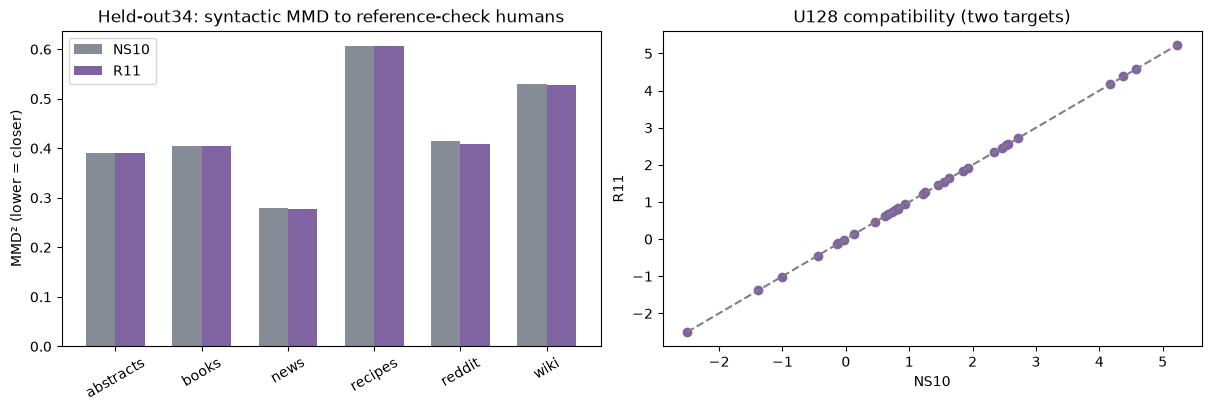

In [9]:
align_rows=[];temporal_rows=[]
for (partition,domain),g in final.groupby(['partition','domain']):
    if domain not in MODELS or not MODELS[domain]['active']:continue
    pack=MODELS[domain];ix=pack['active'];H=pack['syntax']['H'][:,ix]
    check=humans.loc[humans.domain.eq(domain)&humans.reference_role.eq('check')]
    C=np.stack([zvector(t,domain)[ix] for t in check.text])
    for stage,texts in [('NS10',originals.loc[g.case_id,'text'].tolist()),('R11',g.text.tolist())]:
        X=np.stack([zvector(t,domain)[ix] for t in texts])
        align_rows.append(dict(partition=partition,domain=domain,stage=stage,cases=len(g),
            band_loss=float(np.mean([band_loss(t,domain) for t in texts])),
            MMD_fit=mmd(X,H,pack['sigma']),MMD_reference_check=mmd(X,C,pack['sigma']),
            objective=objective(texts,domain,partition)))
for r in final.itertuples():
    for stage,text in [('NS10',originals.loc[r.case_id,'text']),('R11',r.text)]:
        record=json.loads(temporal_path(text).read_text())
        temporal_rows.append(dict(case_id=r.case_id,partition=r.partition,stage=stage,
            **{k:record.get(k) for k in ['U128_2','U128_8','tail4','tail6','tail8','eligible']}))
alignment=pd.DataFrame(align_rows);temporal_results=pd.DataFrame(temporal_rows)
save_csv(alignment,OUT/'alignment_results.csv');save_csv(temporal_results,OUT/'temporal_results.csv')
feature_rows=[];surface_rows=[]
for r in final.itertuples():
    if r.domain not in MODELS:continue
    for stage,text in [('NS10',originals.loc[r.case_id,'text']),('R11',r.text)]:
        z=zvector(text,r.domain)
        for j,name in enumerate(SYN_NAMES):
            feature_rows.append(dict(case_id=r.case_id,partition=r.partition,domain=r.domain,
                stage=stage,feature=name,z=float(z[j]),active=j in MODELS[r.domain]['active']))
    a=zvector(originals.loc[r.case_id,'text'],r.domain,'surface');b=zvector(r.text,r.domain,'surface')
    for j,name in enumerate(SURFACE_NAMES):
        surface_rows.append(dict(case_id=r.case_id,feature=name,delta_z=float(b[j]-a[j])))
save_csv(pd.DataFrame(feature_rows),OUT/'syntactic_features_by_case.csv')
save_csv(pd.DataFrame(surface_rows),OUT/'protected_surface_changes.csv')
display(alignment.round(4))
if len(logs):display(pd.DataFrame(logs).reason.value_counts().rename('decisions').to_frame())
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
if len(alignment):
    plot=alignment.loc[alignment.partition.eq('heldout34')]
    domains=sorted(plot.domain.unique());x=np.arange(len(domains))
    for stage,offset,color in [('NS10',-.17,'#858C96'),('R11',.17,'#8064A2')]:
        s=plot.loc[plot.stage.eq(stage)].set_index('domain').reindex(domains)
        axs[0].bar(x+offset,s.MMD_reference_check,width=.34,label=stage,color=color)
    axs[0].set_xticks(x,domains,rotation=30);axs[0].legend()
axs[0].set(title='Held-out34: syntactic MMD to reference-check humans',ylabel='MMD² (lower = closer)')
t=temporal_results.loc[temporal_results.partition.eq('heldout34')].pivot(index='case_id',columns='stage',values='U128_2').dropna()
if len(t):
    axs[1].scatter(t.NS10,t.R11,color='#8064A2');lo=t.min().min();hi=t.max().max()
    axs[1].plot([lo,hi],[lo,hi],'--',color='gray')
axs[1].set(title='U128 compatibility (two targets)',xlabel='NS10',ylabel='R11')
for ext in ['png','pdf']:fig.savefig(OUT/'figures'/('R00_alignment.'+ext),dpi=200)
plt.show();plt.close(fig)


## 8. Evaluation-only RoBERTa panel

Score OG, NEW, NS10, and R11 against Frozen, RAID-only continuation, and the already adapted detector. Human references are the same RAID validation/test populations, weighted to the 34 held-out domains. Recompute all scores in this environment for consistency; do not mix historical runtime scores with new ones. All models stay frozen, and these scores never feed back into candidate selection.

Figures combine all conditions: a single stage plot and a single TPR staircase panel. The staircase uses validation-human thresholds and realized test-human FPR; AUROC uses the full score ranking. Bootstrap intervals hold human references and models fixed. This tests resistance to the **existing NS10-adapted detector**, not resistance to a newly R11-adapted detector.


Frozen 25 / 362
Frozen 50 / 362
Frozen 75 / 362
Frozen 100 / 362
Frozen 125 / 362
Frozen 150 / 362
Frozen 175 / 362
Frozen 200 / 362
Frozen 225 / 362
Frozen 250 / 362
Frozen 275 / 362
Frozen 300 / 362
Frozen 325 / 362
Frozen 350 / 362
RAID-only 25 / 362
RAID-only 50 / 362
RAID-only 75 / 362
RAID-only 100 / 362
RAID-only 125 / 362
RAID-only 150 / 362
RAID-only 175 / 362
RAID-only 200 / 362
RAID-only 225 / 362
RAID-only 250 / 362
RAID-only 275 / 362
RAID-only 300 / 362
RAID-only 325 / 362
RAID-only 350 / 362
Adapted 25 / 362
Adapted 50 / 362
Adapted 75 / 362
Adapted 100 / 362
Adapted 125 / 362
Adapted 150 / 362
Adapted 175 / 362
Adapted 200 / 362
Adapted 225 / 362
Adapted 250 / 362
Adapted 275 / 362
Adapted 300 / 362
Adapted 325 / 362
Adapted 350 / 362


,arm,stage,cases,AUROC,ci_low,ci_high,mean_AI_score
0,Frozen,OG,34,0.9917,0.9829,0.9975,0.9412
1,Frozen,NEW,34,1.0000,1.0000,1.0000,0.9982
2,Frozen,NS10,34,0.7291,0.6262,0.8243,0.1863
3,Frozen,R11,34,0.7291,0.6246,0.8260,0.1862
4,RAID-only,OG,34,0.9898,0.9803,0.9964,0.9521
5,RAID-only,NEW,34,0.9993,0.9982,1.0000,0.9992
6,RAID-only,NS10,34,0.7705,0.6801,0.8542,0.3632
7,RAID-only,R11,34,0.7676,0.6740,0.8537,0.3632
8,Adapted,OG,34,0.9951,0.9911,0.9981,0.9713
9,Adapted,NEW,34,0.9994,0.9987,1.0000,0.9995


,arm,comparison,AUROC_delta,ci_low,ci_high
0,Frozen,R11_minus_NS10,0.0000,-0.0038,0.0052
1,RAID-only,R11_minus_NS10,-0.0029,-0.0083,0.0019
2,Adapted,R11_minus_NS10,-0.0002,-0.0007,0.0000


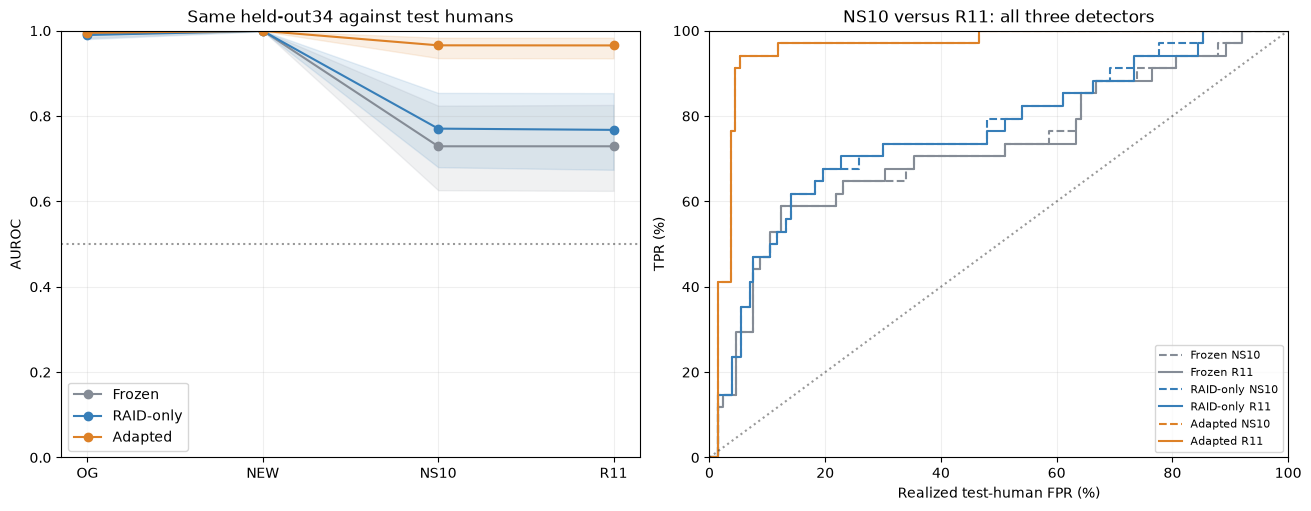

R11: ../results/causal/R00_syntactic_alignment_v1/R11_texts.csv
Manual review: ../results/causal/R00_syntactic_alignment_v1/manual_review.csv
Unchanged cases: 38 /54. No-edit cases are retained in every analysis.


In [10]:
checkpoints={'Frozen':C07/'best_model','RAID-only':AD/'raid_only_control/best_model','Adapted':AD/'best_model'}
for path in checkpoints.values():assert (path/'config.json').exists(),path
eval_pins={}
for arm,path in checkpoints.items():
    weight_files=sorted(path.glob('*.safetensors')) or sorted(path.glob('pytorch_model*.bin'))
    assert weight_files
    eval_pins[arm]={p.name:file_sha(p) for p in weight_files}
freeze(OUT/'evaluation_checkpoints.json',eval_pins)
new_path=ROOT/'results/causal/C06_NEW_step4_Ghostbuster_v1/NEW_inputs_54.csv'
new=pd.read_csv(new_path,keep_default_na=False).set_index('case_id').loc[test_ids].reset_index()
ref=ns.set_index('case_id').loc[test_ids]
assert new.source_id.tolist()==ref.source_id.tolist()
OG=ref.reset_index()[['case_id','source_id','domain']]
OG['text']=OG.source_id.map(raid.set_index('source_id').text)
parts=[]
for stage,frame in [('OG',OG),('NEW',new),('NS10',ns),('R11',final)]:
    f=frame.loc[frame.case_id.isin(test_ids),['case_id','source_id','domain','text']].copy()
    f['stage']=stage;f['split']='test';parts.append(f)
mix=ref.domain.value_counts(normalize=True)
h=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])&raid.domain.isin(mix.index),
    ['source_id','domain','split','text']].copy()
h['case_id']='';h['stage']='Human';parts.append(h)
eval_docs=pd.concat(parts,ignore_index=True);eval_docs['text_sha']=eval_docs.text.map(sha)
eval_frames=[]
for arm,path in checkpoints.items():
    files=sorted(path.glob('*.safetensors')) or sorted(path.glob('pytorch_model*.bin'))
    assert files
    weight_sha=digest(eval_pins[arm])
    etok=AutoTokenizer.from_pretrained(C07/'best_model')
    spec=digest([RUN_SHA,weight_sha,digest(etok.backend_tokenizer.to_str()),512,'bf16_autocast'])
    def ep(sha_):return OUT/'roberta'/(digest([spec,sha_])+'.json')
    pending=[r for r in eval_docs[['text_sha','text']].drop_duplicates().itertuples() if not ep(r.text_sha).exists()]
    if pending:
        model=AutoModelForSequenceClassification.from_pretrained(path,torch_dtype=torch.float32,
            attn_implementation='eager',low_cpu_mem_usage=True).to(DEVICE).eval()
        for i,r in enumerate(pending,1):
            encoded=etok(r.text,return_tensors='pt',truncation=True,max_length=512).to(DEVICE)
            with torch.inference_mode(),torch.autocast(device_type=DEVICE,dtype=torch.bfloat16,enabled=DEVICE=='cuda' and torch.cuda.is_bf16_supported()):
                logits=model(**encoded).logits
            logits=logits.float()[0]
            atomic_json(ep(r.text_sha),dict(AI_score=float(logits.softmax(-1)[1].cpu()),
                AI_log_odds=float((logits[1]-logits[0]).cpu()),scored_tokens=int(encoded.input_ids.shape[1])))
            if i%25==0:print(arm,i,'/',len(pending),flush=True)
        del model;release()
    f=eval_docs.drop(columns='text').copy();f['arm']=arm
    for col in ['AI_score','AI_log_odds','scored_tokens']:
        f[col]=[json.loads(ep(s).read_text())[col] for s in f.text_sha]
    eval_frames.append(f)
    del etok;release()
scores=pd.concat(eval_frames,ignore_index=True);save_csv(scores,OUT/'roberta_scores.csv')

summary=[];stairs=[];paired=[]
rng=np.random.default_rng(CFG['seed']);indices=rng.integers(0,34,(10000,34))
for arm in checkpoints:
    f=scores.loc[scores.arm.eq(arm)];refs_={}
    for split_ in ['validation','test']:
        human=f.loc[f.stage.eq('Human')&f.split.eq(split_)].copy()
        counts=human.domain.value_counts();human['weight']=[mix[d]/counts[d] for d in human.domain]
        assert np.isclose(human.weight.sum(),1);refs_[split_]=human
    cal,hum=refs_['validation'],refs_['test'];hs=hum.AI_score.to_numpy();hw=hum.weight.to_numpy()
    cuts=np.r_[np.inf,np.unique(cal.AI_score)[::-1],-np.inf];aucparts={}
    for stage in ['OG','NEW','NS10','R11']:
        ai=f.loc[f.stage.eq(stage)].set_index('case_id').loc[test_ids];a=ai.AI_score.to_numpy()
        v=(((a[:,None]>hs)+.5*(a[:,None]==hs))*hw).sum(1);aucparts[stage]=v
        low,high=np.quantile(v[indices].mean(1),[.025,.975])
        summary.append(dict(arm=arm,stage=stage,cases=34,AUROC=float(v.mean()),
            ci_low=float(low),ci_high=float(high),mean_AI_score=float(a.mean())))
        for c in cuts:stairs.append(dict(arm=arm,stage=stage,threshold=c,
            calibration_FPR=float(cal.loc[cal.AI_score>c,'weight'].sum()),
            test_FPR=float(hw[hs>c].sum()),TPR=float((a>c).mean())))
    d=aucparts['R11']-aucparts['NS10'];lo,hi=np.quantile(d[indices].mean(1),[.025,.975])
    paired.append(dict(arm=arm,comparison='R11_minus_NS10',AUROC_delta=float(d.mean()),ci_low=float(lo),ci_high=float(hi)))
summary=pd.DataFrame(summary);staircase=pd.DataFrame(stairs);paired=pd.DataFrame(paired)
for name,frame in [('roberta_summary',summary),('roberta_staircase',staircase),('roberta_paired_changes',paired)]:
    save_csv(frame,OUT/(name+'.csv'))
display(summary.round(4));display(paired.round(4))
colors={'Frozen':'#858C96','RAID-only':'#377EB8','Adapted':'#DD8127'}
fig,axs=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
stages=['OG','NEW','NS10','R11'];x=np.arange(4)
for arm,color in colors.items():
    s=summary.loc[summary.arm.eq(arm)].set_index('stage').loc[stages]
    axs[0].plot(x,s.AUROC,'o-',color=color,label=arm)
    axs[0].fill_between(x,s.ci_low,s.ci_high,color=color,alpha=.12)
    for stage,style in [('NS10','--'),('R11','-')]:
        st=staircase.loc[staircase.arm.eq(arm)&staircase.stage.eq(stage)]
        axs[1].step(st.test_FPR*100,st.TPR*100,where='post',color=color,ls=style,label=arm+' '+stage)
axs[0].set_xticks(x,stages);axs[0].set(ylim=(0,1),ylabel='AUROC',title='Same held-out34 against test humans');axs[0].legend()
axs[0].axhline(.5,color='black',ls=':',alpha=.4)
axs[1].plot([0,100],[0,100],':',color='black',alpha=.4)
axs[1].set(xlim=(0,100),ylim=(0,100),xlabel='Realized test-human FPR (%)',ylabel='TPR (%)',title='NS10 versus R11: all three detectors')
axs[1].legend(fontsize=8)
for ax in axs:ax.grid(alpha=.2)
for ext in ['png','pdf']:fig.savefig(OUT/'figures'/('R00_RoBERTa_comparison.'+ext),dpi=200)
plt.show();plt.close(fig)
print('R11:',OUT/'R11_texts.csv')
print('Manual review:',OUT/'manual_review.csv')
print('Unchanged cases:',int((~final.changed).sum()),'/54. No-edit cases are retained in every analysis.')


## Interpretation and next experiments

- **First check edit acceptance.** If most proposals fail, report the candidate generator/constraints as the bottleneck. Do not call no-edit outcomes neutralization failures or successes.
- Better syntactic alignment without lower adapted RoBERTa AUROC would weaken the claim that these particular measurements capture its residual signature.
- Lower frozen/adapted scores alone do not demonstrate feature neutralization. Inspect reference-check MMD, feature changes, content, and compatibility.
- This notebook guards selected surface statistics plus recomputed U128 and surprisal tails. It **does not certify compatibility with all FZ, Ghostbuster, WaveDetect or Binoculars features**. Re-score `R11_texts.csv` with those frozen evaluation pipelines before making that claim. A new R11 adaptation experiment also remains necessary.
- All candidate and final texts are saved separately from NS10. The 20/34 partition is unchanged. Joint search is partition-local; it uses no test-human reference statistics and no detector labels/scores.
- No external adversarial-paraphrasing baseline is reproduced here. That is a distinct compatibility experiment; this notebook tests the proposed feature-alignment method first.

### Primary sources

1. Iyyer et al. (2018), *Adversarial Example Generation with Syntactically Controlled Paraphrase Networks*: https://aclanthology.org/N18-1170/
2. Li et al. (2020), *BERT-ATTACK*: https://aclanthology.org/2020.emnlp-main.500/
3. Wang et al. (2024), *RAFT*: https://aclanthology.org/2024.emnlp-main.939/
4. Cheng et al. (2025), *Adversarial Paraphrasing*: https://arxiv.org/abs/2506.07001
5. FLAN-T5-base: https://huggingface.co/google/flan-t5-base
6. NLI model and label mapping: https://huggingface.co/cross-encoder/nli-deberta-v3-small
7. Qwen scorer: https://huggingface.co/Qwen/Qwen3-0.6B-Base

**Validation performed when preparing this notebook:** notebook schema and Python syntax; synthetic checks of the objective, two-sided bands, replacement offsets, partition alignment and resume semantics. GPU generation and research-data results must be produced in your environment.
